<a href="https://colab.research.google.com/github/Muhammad-Zawar123/SOC-AUTOMATION-/blob/main/final_research_paper_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os, time, warnings, subprocess, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from getpass import getpass
from IPython.display import display

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (f1_score, precision_score, recall_score,
                             classification_report, ConfusionMatrixDisplay)

# Hide only the harmless "mixed types" warning from pandas
warnings.filterwarnings("ignore", category=pd.errors.DtypeWarning)

# ---------------- settings ----------------
DATA_DIR            = "/content/data"
CSV_PATH            = f"{DATA_DIR}/GUIDE_Train.csv"
SEED                = 42
CHUNK_SIZE          = 200_000    # rows read at a time (keeps memory low)
CHUNK_KEEP_FRACTION = 0.20       # share of each chunk we keep
SAMPLE_SIZE         = 150_000    # final sample size
MISSING_THRESHOLD   = 0.40       # drop columns missing more than 40% of values
TEST_SIZE           = 0.20       # 80% train / 20% test
N_RUNS              = 3          # timing runs per model (use 1 for a quick run)

In [ ]:
if os.path.exists(CSV_PATH):
    print("Dataset already downloaded.")
else:
    os.environ["KAGGLE_API_TOKEN"] = getpass("Paste your Kaggle API token (hidden): ")
    os.makedirs(DATA_DIR, exist_ok=True)
    result = subprocess.run(
        ["kaggle", "datasets", "download", "-d", "microsoft/microsoft-security-incident-prediction",
         "-p", DATA_DIR, "--unzip"],
        capture_output=True, text=True)
    print(result.stdout[-400:])
    if result.returncode != 0:
        raise RuntimeError("Download failed:\n" + result.stderr)
    print("Download complete.")

print(os.listdir(DATA_DIR))

Paste your Kaggle API token (hidden): ··········
Dataset URL: https://www.kaggle.com/datasets/microsoft/microsoft-security-incident-prediction
License(s): other


Download complete.
['GUIDE_Train.csv', 'GUIDE_Test.csv', 'GUIDE_Test_Queue_Rankings.csv']


In [ ]:
chunks, total_rows = [], 0
for chunk in pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE):
    total_rows += len(chunk)
    chunks.append(chunk.sample(frac=CHUNK_KEEP_FRACTION, random_state=SEED))

df = pd.concat(chunks, ignore_index=True)
del chunks
df = df.sample(n=min(SAMPLE_SIZE, len(df)), random_state=SEED)

print(f"Rows in the full file : {total_rows:,}")
print(f"Rows in our sample    : {len(df):,}  ({len(df) / total_rows:.2%} of the file)")
print(f"Columns               : {df.shape[1]}")
print()
print(df["IncidentGrade"].value_counts(dropna=False))

Rows in the full file : 9,516,837
Rows in our sample    : 150,000  (1.58% of the file)
Columns               : 45

IncidentGrade
BenignPositive    64844
TruePositive      52276
FalsePositive     32067
NaN                 813
Name: count, dtype: int64


In [ ]:
ID_COLS = [
    "Id", "OrgId", "IncidentId", "AlertId", "AlertTitle", "DeviceId", "Sha256", "IpAddress",
    "Url", "AccountSid", "AccountUpn", "AccountObjectId", "AccountName", "DeviceName",
    "NetworkMessageId", "RegistryKey", "RegistryValueName", "RegistryValueData",
    "ApplicationId", "ApplicationName", "OAuthApplicationId", "FileName", "FolderPath",
    "ResourceIdName",
]

# 1) rows without a label
df = df.dropna(subset=["IncidentGrade"])

# 2) mostly-empty columns
missing_share = df.isna().mean()
sparse_cols = missing_share[missing_share > MISSING_THRESHOLD].index.tolist()
df = df.drop(columns=sparse_cols)

# 3) identifier columns
id_cols_present = [c for c in ID_COLS if c in df.columns]
df = df.drop(columns=id_cols_present)

print("Dropped (more than 40% missing):", sparse_cols)
print("Dropped (identifier columns)   :", len(id_cols_present), "columns")
print("Rows left:", len(df), "| Columns left:", df.shape[1])

Dropped (more than 40% missing): ['MitreTechniques', 'ActionGrouped', 'ActionGranular', 'EmailClusterId', 'ThreatFamily', 'ResourceType', 'Roles', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict']
Dropped (identifier columns)   : 24 columns
Rows left: 149187 | Columns left: 11


In [ ]:
# DetectorId -> how often the detector appears (one column instead of thousands)
detector_freq = df["DetectorId"].value_counts()
df["DetectorId_Freq"] = df["DetectorId"].map(detector_freq)
df = df.drop(columns=["DetectorId"])

# Timestamp -> hour of day and day of week
ts = pd.to_datetime(df["Timestamp"])
df["HourOfDay"] = ts.dt.hour
df["DayOfWeek"] = ts.dt.dayofweek          # 0 = Monday ... 6 = Sunday
df = df.drop(columns=["Timestamp"])

# One-Hot Encoding for the low-cardinality text columns
df = pd.get_dummies(df, columns=["Category", "EntityType", "EvidenceRole"])

# Label -> numbers
LABELS = {"FalsePositive": 0, "BenignPositive": 1, "TruePositive": 2}
CLASS_NAMES = ["FalsePositive", "BenignPositive", "TruePositive"]
df["IncidentGrade"] = df["IncidentGrade"].map(LABELS)

# Sanity checks
assert df.select_dtypes(include="object").shape[1] == 0, "Some text columns were not encoded"
assert df.isna().sum().sum() == 0, "Some missing values are left"
print("Final table:", df.shape)


Final table: (149187, 53)


In [ ]:
X = df.drop(columns=["IncidentGrade"])
y = df["IncidentGrade"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=SEED, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print("Training set:", X_train.shape)
print("Test set    :", X_test.shape)

Training set: (119349, 52)
Test set    : (29838, 52)


In [ ]:
def evaluate(name, model, use_scaled):
    Xtr, Xte = (X_train_s, X_test_s) if use_scaled else (X_train, X_test)
    fit_times, predict_times = [], []

    for _ in range(N_RUNS):
        m = clone(model)
        t0 = time.perf_counter()
        m.fit(Xtr, y_train)
        fit_times.append(time.perf_counter() - t0)

        t0 = time.perf_counter()
        y_pred = m.predict(Xte)
        predict_times.append(time.perf_counter() - t0)

    # Model size on disk
    tmp = "/tmp/_model_size_check.pkl"
    joblib.dump(m, tmp)
    size_mb = os.path.getsize(tmp) / 1e6
    os.remove(tmp)

    predict_time = float(np.mean(predict_times))
    row = {
        "Model": name,
        "Macro-F1":  f1_score(y_test, y_pred, average="macro"),
        "Precision": precision_score(y_test, y_pred, average="macro"),
        "Recall":    recall_score(y_test, y_pred, average="macro"),
        "Train time (s)":      float(np.mean(fit_times)),
        "Inference time (s)":  predict_time,
        "ms per 1,000 alerts": predict_time / len(X_test) * 1000 * 1000,
        "Model size (MB)":     size_mb,
    }
    return row, m, y_pred


experiments = [
    ("Logistic Regression", LogisticRegression(max_iter=1000, random_state=SEED), True),
    ("Decision Tree",       DecisionTreeClassifier(random_state=SEED),            False),
    ("Random Forest",       RandomForestClassifier(n_estimators=100, random_state=SEED), False),
]

rows, trained = [], {}
for name, model, use_scaled in experiments:
    print(f"Training {name} ...", flush=True)
    row, fitted, preds = evaluate(name, model, use_scaled)
    rows.append(row)
    trained[name] = (fitted, preds)

results = pd.DataFrame(rows)
print("Done.")

Training Logistic Regression ...
Training Decision Tree ...
Training Random Forest ...
Done.


In [ ]:
display(results.round({
    "Macro-F1": 4, "Precision": 4, "Recall": 4,
    "Train time (s)": 2, "Inference time (s)": 4,
    "ms per 1,000 alerts": 2, "Model size (MB)": 4,
}))

results.to_csv("results_table.csv", index=False)

,Model,Macro-F1,Precision,Recall,Train time (s),Inference time (s),"ms per 1,000 alerts",Model size (MB)
0,Logistic Regression,0.5235,0.6332,0.5383,8.68,0.0214,0.72,0.0021
1,Decision Tree,0.7347,0.7420,0.7298,0.69,0.0166,0.56,2.6877
2,Random Forest,0.7287,0.7438,0.7202,22.79,1.1950,40.05,276.4026


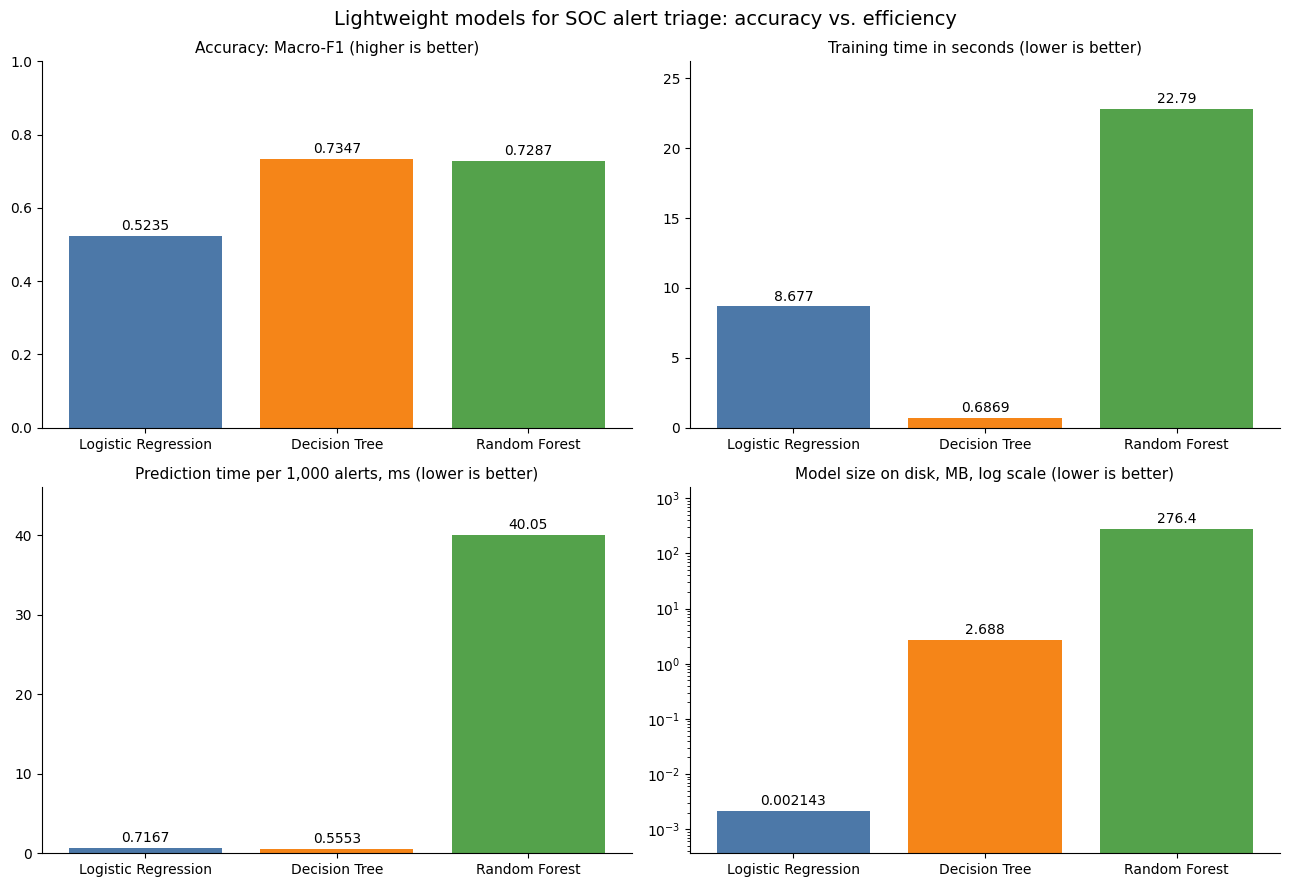

In [ ]:
colors = ["#4C78A8", "#F58518", "#54A24B"]
panels = [
    ("Macro-F1",            "Accuracy: Macro-F1 (higher is better)",                    False),
    ("Train time (s)",      "Training time in seconds (lower is better)",               False),
    ("ms per 1,000 alerts", "Prediction time per 1,000 alerts, ms (lower is better)",   False),
    ("Model size (MB)",     "Model size on disk, MB, log scale (lower is better)",      True),
]

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (col, title, use_log) in zip(axes.ravel(), panels):
    bars = ax.bar(results["Model"], results[col], color=colors[:len(results)])
    ax.set_title(title, fontsize=11)
    if use_log:
        ax.set_yscale("log")
    if col == "Macro-F1":
        ax.set_ylim(0, 1)
    ax.bar_label(bars, fmt="%.4g", fontsize=10, padding=2)
    ax.margins(y=0.15)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Lightweight models for SOC alert triage: accuracy vs. efficiency", fontsize=14)
fig.tight_layout()
fig.savefig("comparison_charts.png", dpi=200, bbox_inches="tight")
plt.show()

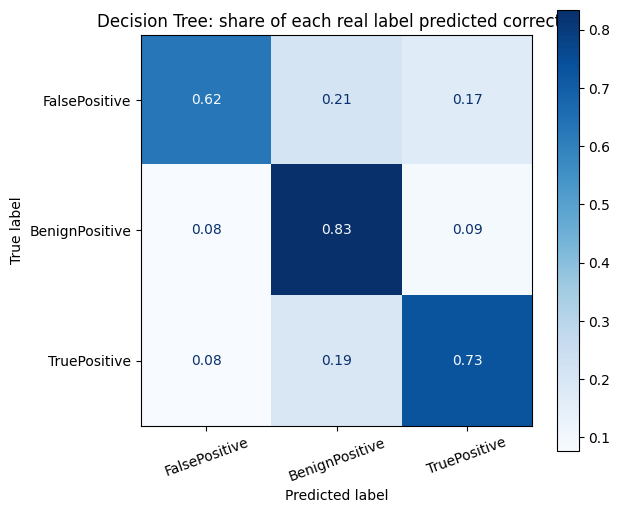

                precision    recall  f1-score   support

 FalsePositive      0.686     0.625     0.654      6414
BenignPositive      0.765     0.834     0.798     12969
  TruePositive      0.775     0.731     0.752     10455

      accuracy                          0.753     29838
     macro avg      0.742     0.730     0.735     29838
  weighted avg      0.752     0.753     0.751     29838



In [ ]:
best_name = results.loc[results["Macro-F1"].idxmax(), "Model"]
_, best_pred = trained[best_name]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_pred, display_labels=CLASS_NAMES,
    normalize="true", cmap="Blues", values_format=".2f", ax=ax)
ax.set_title(f"{best_name}: share of each real label predicted correctly")
plt.xticks(rotation=20)
fig.tight_layout()
fig.savefig("confusion_matrix.png", dpi=200, bbox_inches="tight")
plt.show()

print(classification_report(y_test, best_pred, target_names=CLASS_NAMES, digits=3))

In [ ]:
best     = results.loc[results["Macro-F1"].idxmax()]
smallest = results.loc[results["Model size (MB)"].idxmin()]
fastest  = results.loc[results["ms per 1,000 alerts"].idxmin()]

print(f"Most accurate : {best['Model']} (Macro-F1 {best['Macro-F1']:.4f})")
print(f"Smallest      : {smallest['Model']} ({smallest['Model size (MB)'] * 1000:.1f} KB)")
print(f"Fastest       : {fastest['Model']} ({fastest['ms per 1,000 alerts']:.2f} ms per 1,000 alerts)")

if best["Model"] != smallest["Model"]:
    print()
    print(f"{best['Model']} is {best['Model size (MB)'] / smallest['Model size (MB)']:,.0f}x larger than "
          f"{smallest['Model']}, and gains {best['Macro-F1'] - smallest['Macro-F1']:.3f} Macro-F1.")

Most accurate : Decision Tree (Macro-F1 0.7347)
Smallest      : Logistic Regression (2.1 KB)
Fastest       : Decision Tree (0.56 ms per 1,000 alerts)

Decision Tree is 1,254x larger than Logistic Regression, and gains 0.211 Macro-F1.


In [ ]:
print("Shape:", df.shape)
print()
df.info()
display(df.head())
print()
print("Label share in % (0 = False Positive, 1 = Benign Positive, 2 = True Positive):")
print((df["IncidentGrade"].value_counts(normalize=True) * 100).round(1).sort_index())

Shape: (149187, 53)

<class 'pandas.core.frame.DataFrame'>
Index: 149187 entries, 268893 to 1010226
Data columns (total 53 columns):
 #   Column                           Non-Null Count   Dtype
---  ------                           --------------   -----
 0   IncidentGrade                    149187 non-null  int64
 1   OSFamily                         149187 non-null  int64
 2   OSVersion                        149187 non-null  int64
 3   CountryCode                      149187 non-null  int64
 4   State                            149187 non-null  int64
 5   City                             149187 non-null  int64
 6   DetectorId_Freq                  149187 non-null  int64
 7   HourOfDay                        149187 non-null  int32
 8   DayOfWeek                        149187 non-null  int32
 9   Category_Collection              149187 non-null  bool 
 10  Category_CommandAndControl       149187 non-null  bool 
 11  Category_CredentialAccess        149187 non-null  bool 
 12  Category

,IncidentGrade,OSFamily,OSVersion,CountryCode,State,City,DetectorId_Freq,HourOfDay,DayOfWeek,Category_Collection,...,EntityType_Nic,EntityType_OAuthApplication,EntityType_Process,EntityType_RegistryKey,EntityType_RegistryValue,EntityType_SecurityGroup,EntityType_Url,EntityType_User,EvidenceRole_Impacted,EvidenceRole_Related
268893,2,5,66,242,1445,10630,6401,8,0,False,...,False,False,False,False,False,False,False,False,False,True
456340,0,5,66,242,1445,10630,12078,18,2,False,...,False,False,False,False,False,False,False,True,True,False
872959,1,5,66,242,1445,10630,5211,13,3,False,...,False,False,False,False,False,False,False,True,True,False
834645,1,5,66,242,1445,10630,860,18,1,False,...,False,False,False,False,False,False,False,False,False,True
370969,1,5,66,242,1445,10630,560,11,2,False,...,False,False,False,False,False,False,False,False,True,False



Label share in % (0 = False Positive, 1 = Benign Positive, 2 = True Positive):
IncidentGrade
0    21.5
1    43.5
2    35.0
Name: proportion, dtype: float64


In [ ]:
import sys
print("Python:", sys.version.split()[0])
!lscpu | grep -E "Model name|^CPU\(s\)"

Python: 3.13.16
CPU(s):                                  2
Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz


In [ ]:
KGAT_9b0fb5d0c02e93fd5c7a7ade00ac13fb